In [1]:
import torch
import torchvision
assert int(torch.__version__.split(".")[1]) >= 12 or int(torch.__version__.split(".")[0]) == 2, "torch version should be 1.12+"
assert int(torchvision.__version__.split(".")[1]) >= 13, "torchvision version should be 0.13+"
print(f"torch version: {torch.__version__}")
print(f"torchvision version: {torchvision.__version__}")

torch version: 2.12.0+cu126
torchvision version: 0.27.0+cu126


In [2]:
import matplotlib.pyplot as plt
import torch
import torchvision

from torch import nn
import torchvision.transforms.v2 as T

from torchinfo import summary

from going_modular import data_setup, engine
from helper_functions import download_data, set_seeds, plot_loss_curves

In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

# 1. Get Data

In [4]:
# Download pizza, steak, sushi images from GitHub
image_path = download_data(source="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip",
                           destination="pizza_steak_sushi")
image_path

[INFO] data\pizza_steak_sushi directory exists, skipping download.


WindowsPath('data/pizza_steak_sushi')

In [5]:
# Setup directory paths to train and test images
train_dir = image_path / "train"
test_dir = image_path / "test"

# 2. Create Datasets and DataLoaders

In [6]:
IMAGE_SIZE = 224
BATCH_SIZE = 32

transforms = T.Compose([
    T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    T.ToImage(),
    T.ToDtype(torch.float32, True)
])

train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(train_dir, test_dir, transforms, transforms, BATCH_SIZE, 0, True)

(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

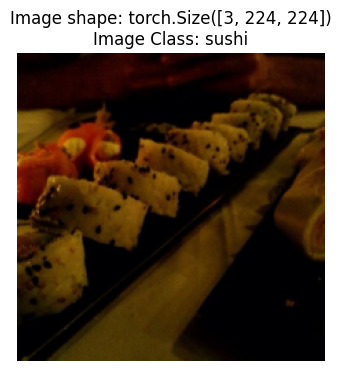

In [7]:
# 可视化一张图片
images, labels = next(iter(train_dataloader))
image, label = images[0], labels[0]

plt.figure(figsize=(4, 4))
plt.imshow(image.permute(1, 2, 0))
plt.title(f"Image shape: {image.shape}\nImage Class: {class_names[label]}")
plt.axis(False)

# 3. Replicating the ViT paper

## 3.1 Equation-1
分patches, embedding

$$
\begin{aligned}
\mathbf{z}_{0} &=\left[\mathbf{x}_{\text {class }} ; \mathbf{x}_{p}^{1} \mathbf{E} ; \mathbf{x}_{p}^{2} \mathbf{E} ; \cdots ; \mathbf{x}_{p}^{N} \mathbf{E}\right]+\mathbf{E}_{\text {pos }}, & & \mathbf{E} \in \mathbb{R}^{\left(P^{2} \cdot C\right) \times D}, \mathbf{E}_{\text {pos }} \in \mathbb{R}^{(N+1) \times D}
\end{aligned}
$$

### 3.1.1 手动尝试计算各个参数

In [8]:
# 假设 patch_size = 16
patch_size = 16
image_size, width, height = 224, 224, 224
color_channels = 3

num_patches = width * height // (patch_size * patch_size)

assert(width * height % (patch_size * patch_size) == 0)

print(f"原图像大小: [W, H, C] -> {width} x {height} x {color_channels}")
print(f"Patch个数: {num_patches} | 每个Patch Image大小: [W, H, C] -> {patch_size} x {patch_size} x {color_channels} | After Flattern Shape: {num_patches} x {patch_size * patch_size * color_channels}")

原图像大小: [W, H, C] -> 224 x 224 x 3
Patch个数: 196 | 每个Patch Image大小: [W, H, C] -> 16 x 16 x 3 | After Flattern Shape: 196 x 768


### 3.1.2 手动尝试图片切片成patches

(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

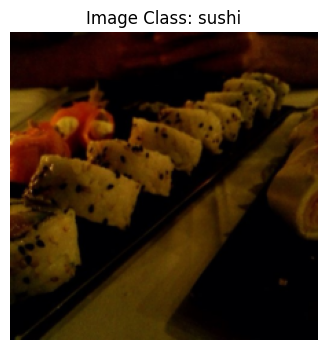

In [9]:
# plot 单张图片
plt.figure(figsize=(4, 4))
plt.imshow(image.permute(1, 2, 0))
plt.title(f"Image Class: {class_names[label]}")
plt.axis(False)

(np.float64(-0.5), np.float64(223.5), np.float64(15.5), np.float64(-0.5))

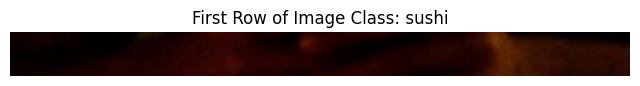

In [10]:
# 取单张图片的第一行
plt.figure(figsize=(8, 8))
plt.imshow(image[:, :patch_size, :].permute(1, 2, 0)) # width和color全选
plt.title(f"First Row of Image Class: {class_names[label]}")
plt.axis(False)

num_patches_per_row: 14


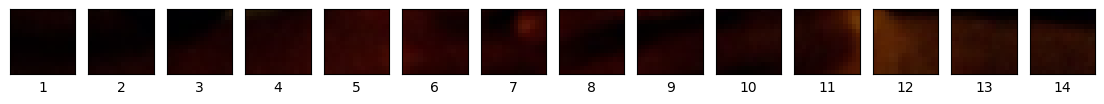

In [11]:
# 单张图片的第一行分patch
image_size = 224
image_row = image[:, :patch_size, :]

num_patches_per_row = image_size // patch_size
assert(image_size % patch_size == 0)
print(f"num_patches_per_row: {num_patches_per_row}")

fig, ax = plt.subplots(nrows= 1, 
                       ncols= num_patches_per_row,
                       figsize=(num_patches_per_row, num_patches_per_row), 
                       sharex=True, 
                       sharey=True)

# i: index, 从1开始
# patch: 从 0 到 width, step 为 patch_size
for i, patch in enumerate(range(0, image_size, patch_size)):
    ax[i].imshow(image_row[:, :, patch:patch + patch_size].permute(1, 2, 0)) # 单行image的[C, H, W]的C, h全选
    ax[i].set_xlabel(i+1) # 最底下标注序号
    ax[i].set_xticks([]) # 隐藏 x 和 y 坐标轴
    ax[i].set_yticks([])

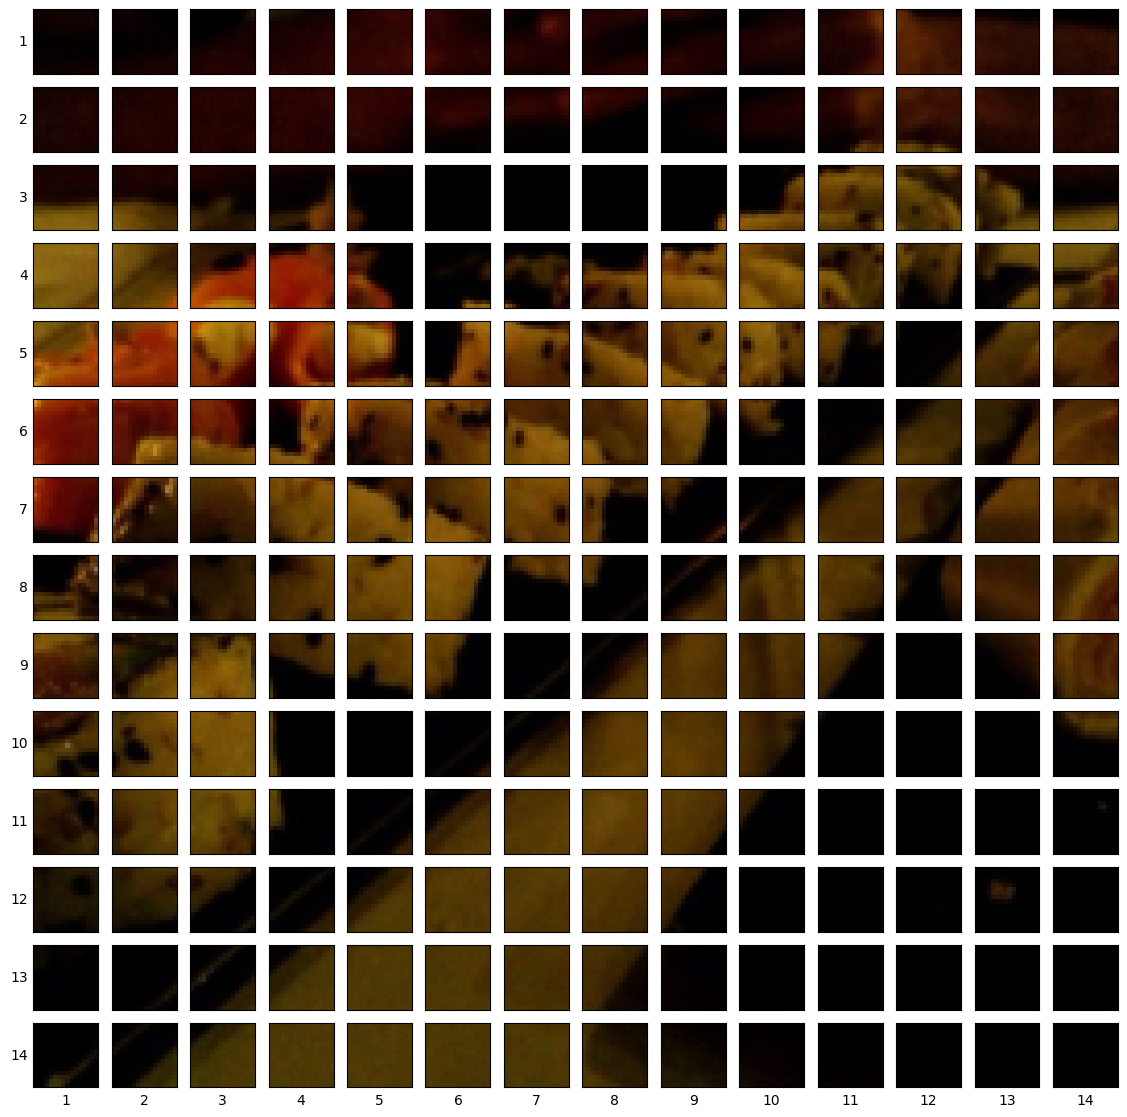

In [12]:
# 整张图片分patch
fig, ax = plt.subplots(nrows= num_patches_per_row, 
                       ncols= num_patches_per_row,
                       figsize=(num_patches_per_row, num_patches_per_row), 
                       sharex=True,
                       sharey=True)
for i, patch_y in enumerate(range(0, image_size, patch_size)):
    image_row = image[:, patch_y:patch_y + patch_size, :]
    for j, patch_x in enumerate(range(0, image_size, patch_size)):
        ax[i, j].imshow(image_row[:, :, patch_x:patch_x + patch_size].permute(1, 2, 0)) # 单行image的[C, H, W]的C, h全选
        ax[i, j].set_xticks([]) # 隐藏 x 和 y 坐标轴
        ax[i, j].set_yticks([])
        ax[i, j].set_ylabel(i+1,
                        rotation="horizontal",
                        horizontalalignment="right",
                        verticalalignment="center")
        ax[i, j].set_xlabel(j+1)
        ax[i, j].label_outer()

### 3.1.3 使用 `Conv2d` 切片图片

In [13]:
hidden_units = 768

conv2d = nn.Conv2d(
    in_channels=3,
    out_channels=hidden_units,
    kernel_size=patch_size,
    stride=patch_size,
    padding=0
)

In [14]:
image_conv_out = conv2d(image.unsqueeze(dim=0))
image_conv_out.shape

torch.Size([1, 768, 14, 14])

`torch.Size([1, 768, 14, 14])` 中 `14 * 14` 是`feature map`的大小, 768是`feature map`的个数

flatten之后就变成 `[768, 196]`, 768 是 `conv2d` 的输出, 

再转置就是目标输出大小 `[196, 768]` (patch_num, embeddings)

同时, 由于conv2d的参数会随着训练变化, 这些feature map也会随着训练变化. 因此 `conv2d + flatten +transpose` 就做到了 `split + embedding` 两个步骤

Showing random convolutional feature maps from indexes: [481, 41, 451, 472, 44]


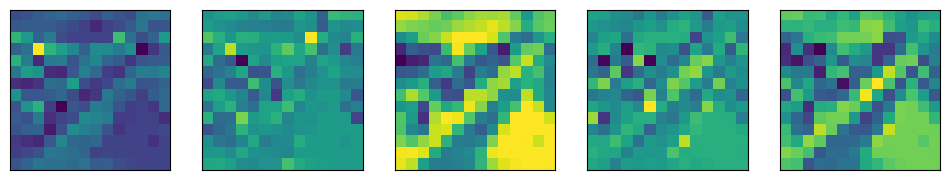

In [15]:
# Plot random 5 convolutional feature maps
import random
random_indexes = random.sample(range(0, 758), k=5) # pick 5 numbers between 0 and the embedding size
print(f"Showing random convolutional feature maps from indexes: {random_indexes}")

# Create plot
fig, axs = plt.subplots(nrows=1, ncols=5, figsize=(12, 12))

# Plot random image feature maps
for i, idx in enumerate(random_indexes):
    image_conv_feature_map = image_conv_out[:, idx, :, :] # index on the output tensor of the convolutional layer
    axs[i].imshow(image_conv_feature_map.squeeze().detach().numpy())
    axs[i].set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])

In [16]:
flatten = nn.Flatten(start_dim=2, end_dim=3) # 只展平 height 和 width

Original image shape: torch.Size([3, 224, 224])
Image feature map shape: torch.Size([1, 768, 14, 14])
Flattened image feature map shape: torch.Size([1, 768, 196])


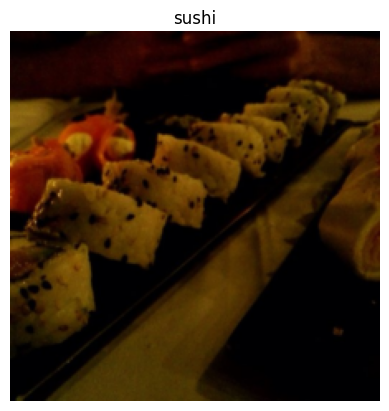

In [17]:
# 1. View single image
plt.imshow(image.permute(1, 2, 0))
plt.title(class_names[label])
plt.axis(False)
print(f"Original image shape: {image.shape}")

# 2. Turn image into feature maps
image_out_of_conv = conv2d(image.unsqueeze(0)) # add batch dimension to avoid shape errors
print(f"Image feature map shape: {image_out_of_conv.shape}")

# 3. Flatten the feature maps
image_out_of_conv_flattened = flatten(image_out_of_conv)
print(f"Flattened image feature map shape: {image_out_of_conv_flattened.shape}")

In [18]:
image_out_of_conv_flattened_reshaped = image_out_of_conv_flattened.permute(0, 2, 1) # [batch_size, P^2•C, N] -> [batch_size, N, P^2•C]
print(f"Patch embedding sequence shape: {image_out_of_conv_flattened_reshaped.shape} -> [batch_size, num_patches, embedding_size]")

Patch embedding sequence shape: torch.Size([1, 196, 768]) -> [batch_size, num_patches, embedding_size]


### 3.1.4 创建 Modle class 应用上面的处理

In [19]:
class PatchEmbedding(nn.Module):
    """Turns a 2D input image into a 1D sequence learnable embedding vector.

    Args:
        in_channels (int): Number of color channels for the input images. Defaults to 3.
        patch_size (int): Size of patches to convert input image into. Defaults to 16.
        embedding_dim (int): Size of embedding to turn image into. Defaults to 768.
    """
    # 2. Initialize the class with appropriate variables
    def __init__(self,
                 in_channels:int=3,
                 patch_size:int=16,
                 embedding_dim:int=768):
        super().__init__()
        self.conv2d = nn.Conv2d(in_channels=in_channels,
                                out_channels=embedding_dim,
                                kernel_size=patch_size,
                                stride=patch_size,
                                padding=0)
        self.flatten = nn.Flatten(start_dim=2, end_dim=3)
    
    def forward(self, x:torch.Tensor) -> torch.Tensor:
        resolution = x.shape[-1]
        
        return self.flatten(self.conv2d(x)).permute(0, 2, 1)

In [20]:
set_seeds()

patchify = PatchEmbedding()
print(f"Input image shape: {image.unsqueeze(0).shape}")
patch_embedded_image = patchify(image.unsqueeze(0)) # add an extra batch dimension on the 0th index, otherwise will error
print(f"Output patch embedding shape: {patch_embedded_image.shape}")

Input image shape: torch.Size([1, 3, 224, 224])
Output patch embedding shape: torch.Size([1, 196, 768])


In [21]:
from torchinfo import summary

summary(model= patchify, input_size=(1, 3, 224, 224),
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                  Input Shape          Output Shape         Param #              Trainable
PatchEmbedding (PatchEmbedding)          [1, 3, 224, 224]     [1, 196, 768]        --                   True
├─Conv2d (conv2d)                        [1, 3, 224, 224]     [1, 768, 14, 14]     590,592              True
├─Flatten (flatten)                      [1, 768, 14, 14]     [1, 768, 196]        --                   --
Total params: 590,592
Trainable params: 590,592
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 115.76
Input size (MB): 0.60
Forward/backward pass size (MB): 1.20
Params size (MB): 2.36
Estimated Total Size (MB): 4.17

### 3.1.5 创建 Class Token Embedding

In [22]:
patch_embedded_image.shape

torch.Size([1, 196, 768])

torch.Size([1, 196, 768]) -> `[ batch_size, patch_num, embedding_dim ]`

我们需要在196个patch前面加一个class token, 最终变成 `[ batch_size, patch_num + 1, embedding_dim ]` = `[ batch_size, 197, embedding_dim ]`

In [23]:
# 使用nn.Parameter创建, 因为需要保证该参数可学习, 需要requires_grad=True
class_token = nn.Parameter(torch.rand(size=(1, 1, 768)),
                           requires_grad=True)
concated_image = torch.cat((class_token, patch_embedded_image), dim=1)

print(f"class_token: {class_token}\n\nclass_token shape: {class_token.shape}\nnew_image_shape: {concated_image.shape}")

class_token: Parameter containing:
tensor([[[1.7499e-01, 1.5875e-01, 4.3898e-01, 1.3299e-01, 7.3946e-01,
          3.2986e-01, 3.7970e-01, 4.2635e-01, 7.3957e-01, 5.7900e-01,
          3.0259e-01, 2.9348e-03, 5.3454e-01, 4.7274e-01, 4.9351e-01,
          9.7968e-01, 7.2336e-01, 8.0824e-01, 7.2428e-01, 9.2200e-01,
          4.7448e-01, 7.2538e-02, 8.5419e-01, 2.5475e-01, 1.8009e-01,
          4.2684e-01, 6.8440e-01, 5.4903e-01, 5.4408e-01, 2.7766e-01,
          1.9044e-01, 8.0705e-01, 5.6778e-01, 8.2807e-02, 6.9329e-01,
          3.7302e-01, 6.6770e-01, 3.3095e-01, 4.1876e-01, 5.1257e-01,
          9.7399e-02, 3.4769e-01, 7.3409e-02, 1.2247e-01, 2.6762e-01,
          3.1503e-01, 9.2572e-01, 4.2552e-01, 1.2040e-01, 4.6172e-01,
          5.2257e-01, 9.6179e-01, 6.8806e-01, 7.6880e-01, 1.8136e-01,
          6.0859e-01, 1.8700e-01, 5.9436e-01, 5.0082e-01, 1.5240e-01,
          8.8812e-01, 5.7892e-01, 8.7767e-01, 9.2158e-01, 2.9898e-02,
          3.5517e-01, 6.2151e-01, 1.4165e-01, 7.9850e-0

### 3.1.6 创建 Position Embedding

In [24]:
num_patches = 196
embedding_dim = 768

position_embedding = nn.Parameter(torch.randn(size=(1, num_patches+1, embedding_dim)), requires_grad=True)

image_patched_with_class_and_embedding = concated_image + position_embedding # 直接相加

print(f"position_embedding shape: {position_embedding.shape}\nfinal_image shape: {image_patched_with_class_and_embedding.shape}")
print(f"\nBefore:\n{concated_image[:,:10,:]}\n\nAfter:\n{image_patched_with_class_and_embedding[:,:10:]}")

position_embedding shape: torch.Size([1, 197, 768])
final_image shape: torch.Size([1, 197, 768])

Before:
tensor([[[ 0.1750,  0.1588,  0.4390,  ...,  0.8962,  0.0503,  0.3243],
         [-0.0335, -0.0277, -0.0308,  ...,  0.0243, -0.0149,  0.0113],
         [-0.0506, -0.0304, -0.0244,  ...,  0.0304, -0.0233,  0.0235],
         ...,
         [-0.1014, -0.0274, -0.0198,  ...,  0.0328, -0.0459,  0.0197],
         [-0.0562, -0.0366, -0.0236,  ...,  0.0161, -0.0460,  0.0285],
         [-0.0494, -0.0456, -0.0027,  ...,  0.0428, -0.0236,  0.0425]]],
       grad_fn=<SliceBackward0>)

After:
tensor([[[-0.0704,  0.1541,  1.9374,  ...,  0.4887,  1.6289, -0.0038],
         [-0.5576, -0.2422,  2.1130,  ..., -0.9297,  1.0079,  0.0372],
         [-0.3615,  1.6147, -0.3345,  ..., -0.5954,  0.0824,  0.6353],
         ...,
         [ 0.2428, -0.0364, -0.7084,  ..., -1.1883, -2.8321,  0.2145],
         [ 0.9632, -0.5475, -0.3318,  ...,  0.2047, -0.4300, -0.6177],
         [-0.4921,  1.4237,  0.1115,  ...,

### 3.1.7 Put it together

公式: 
$$
\begin{aligned}
\mathbf{z}_{0} &=\left[\mathbf{x}_{\text {class }} ; \mathbf{x}_{p}^{1} \mathbf{E} ; \mathbf{x}_{p}^{2} \mathbf{E} ; \cdots ; \mathbf{x}_{p}^{N} \mathbf{E}\right]+\mathbf{E}_{\text {pos }}, & & \mathbf{E} \in \mathbb{R}^{\left(P^{2} \cdot C\right) \times D}, \mathbf{E}_{\text {pos }} \in \mathbb{R}^{(N+1) \times D}
\end{aligned}
$$


In [25]:
image.shape[0]

3

In [26]:
set_seeds()

# 1. patch_size, image_size, num_patches
patch_size = 16 # P
image_size = image.shape[1]
color_channels = image.shape[0]

num_patches = image_size**2 // patch_size**2 # N
assert(image_size**2 % patch_size**2 == 0)

embedding_dim = patch_size**2 * color_channels # D

print(f"patch_size={patch_size}\nimage_size={image_size}\ncolor_channels={color_channels}\nnum_patches={num_patches}\nembedding_dim={embedding_dim}\n")

path_embedding_layer = PatchEmbedding(in_channels=color_channels,
                                      patch_size=patch_size,
                                      embedding_dim=embedding_dim)

# pass single image into the layer
path_embedded_image = path_embedding_layer(image.unsqueeze(dim=0)) # 加一个batch_size dim
print(f"raw_image shpae: {image.unsqueeze(dim=0).shape}")
print(f"path_embedded_image shpae: {path_embedded_image.shape}")

# add class token
class_token = nn.Parameter(torch.randn(size=(1, 1, embedding_dim)), requires_grad=True)
patch_with_class_token = torch.cat((class_token, path_embedded_image), dim=1) # 在num_patches维度接上, class_token放在最开头
print(f"patch_with_class_token shpae: {patch_with_class_token.shape}")

# add positional embedding
position_embedding = nn.Parameter(torch.randn(size=(1, num_patches+1, embedding_dim)), requires_grad=True)
patch_with_class_position_embedding = patch_with_class_token + position_embedding
print(f"patch_with_class_position_embedding shpae: {patch_with_class_position_embedding.shape}")

patch_size=16
image_size=224
color_channels=3
num_patches=196
embedding_dim=768

raw_image shpae: torch.Size([1, 3, 224, 224])
path_embedded_image shpae: torch.Size([1, 196, 768])
patch_with_class_token shpae: torch.Size([1, 197, 768])
patch_with_class_position_embedding shpae: torch.Size([1, 197, 768])


## 3.2 Equation-2

$$
\begin{aligned}
\mathbf{z}_{\ell}^{\prime} &=\operatorname{MSA}\left(\operatorname{LN}\left(\mathbf{z}_{\ell-1}\right)\right)+\mathbf{z}_{\ell-1}, & & \ell=1 \ldots L
\end{aligned}
$$

本部分只实现 MSA(Multihead Self-Attension), 残差连接将在实现整个Transformer Encoder时实现

In [27]:
class MultiheadSelfAttensionBlock(nn.Module):
    def __init__(self, embedding_dim: int=768, num_heads:int = 12, dropout: float=0):
        super().__init__()
        self.norm_layer = nn.LayerNorm(normalized_shape=embedding_dim)
        self.msa = nn.MultiheadAttention(embed_dim=embedding_dim, num_heads=num_heads, dropout=dropout, batch_first=True)
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.norm_layer(x)
        attn_output, _ = self.msa(query=x, key=x, value=x, need_weights=False)
        return attn_output

In [28]:
multihead_attn_block = MultiheadSelfAttensionBlock()
attn_output = multihead_attn_block(patch_with_class_position_embedding)
print(f"Before shape: {patch_with_class_position_embedding.shape}\nAfter shape: {attn_output.shape}")

Before shape: torch.Size([1, 197, 768])
After shape: torch.Size([1, 197, 768])


## 3.3 Equation-3

$$
\begin{aligned}
\mathbf{z}_{\ell} &=\operatorname{MLP}\left(\operatorname{LN}\left(\mathbf{z}_{\ell}^{\prime}\right)\right)+\mathbf{z}_{\ell}^{\prime}, & & \ell=1 \ldots L
\end{aligned}
$$

同样的, 本部分先不会实现残差链接

一些知识点:
1. `MLP` = Multilayer Perceptron 多层感知机. ViT论文中的 `MLP` = `Linear -> GELU -> Linear`, 也就是两层全连接层, 中间加一个GELU激活函数
2. `GELU` = Gaussian Error Linear Unit 高斯误差线性单元, 是一种激活函数, 论文中使用了 `GELU` 激活函数, 而不是常用的 `ReLU` 激活函数.
3. `Linear` = 线性变换, 即全连接层。别名: `Dense layer`, `fully connected layer`, `feedforward layer`

In [29]:
class MLPBlock(nn.Module):
    def __init__(self, embedding_dim: int=768, mlp_size:int =3072, dropout:float =0.1):
        super().__init__()
        self.layer_norm = nn.LayerNorm(normalized_shape=embedding_dim)
        self.mlp = nn.Sequential(
            nn.Linear(in_features=embedding_dim, out_features=mlp_size),
            nn.GELU(),
            nn.Dropout(p=dropout), # 随机丢弃激活后的值
            nn.Linear(in_features=mlp_size, out_features=embedding_dim),
            nn.Dropout(p=dropout)
        )
    
    def forward(self, x: torch.Tensor)-> torch.Tensor:
        x = self.layer_norm(x)
        return self.mlp(x)

In [30]:
mlp_block = MLPBlock()
mlp_output = mlp_block(attn_output)
mlp_output.shape

torch.Size([1, 197, 768])

## 3.4 Create Transformer Encoder

### 3.4.1 用已有custom code 创建 transformer encoder

In [31]:
class TransformerEncoderBlock(nn.Module):
    def __init__(self, embedding_dim: int=768, num_heads: int=12, mlp_size: int=3072, attn_dropout: float=0.1, mpl_dropout: float=0.1):
        super().__init__()
        self.msa_block = MultiheadSelfAttensionBlock(embedding_dim, num_heads, attn_dropout)
        self.mlp_block = MLPBlock(embedding_dim, mlp_size, mpl_dropout)
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.msa_block(x) + x
        x = self.mlp_block(x) + x
        return x

In [32]:
from typing import List, Tuple
from torchinfo import ModelStatistics

def show_model_summary(model: nn.Module,
                       input_size: Tuple[int, ...] | None,
                       col_names: List[str] | None=["input_size", "output_size", "num_params", "trainable"],
                       col_width: int=20,
                       row_settings: List[str]=["var_names"]) -> ModelStatistics:
    return summary(model= model,
            input_size=input_size,
            col_names=col_names,
            col_width=col_width,
            row_settings=row_settings)

In [33]:
patch_with_class_position_embedding.shape

torch.Size([1, 197, 768])

In [34]:
transformer_encoder_block = TransformerEncoderBlock()
print(show_model_summary(model= transformer_encoder_block, input_size= (1, 197, 768)))

Layer (type (var_name))                            Input Shape          Output Shape         Param #              Trainable
TransformerEncoderBlock (TransformerEncoderBlock)  [1, 197, 768]        [1, 197, 768]        --                   True
├─MultiheadSelfAttensionBlock (msa_block)          [1, 197, 768]        [1, 197, 768]        --                   True
│    └─LayerNorm (norm_layer)                      [1, 197, 768]        [1, 197, 768]        1,536                True
│    └─MultiheadAttention (msa)                    --                   [1, 197, 768]        2,362,368            True
├─MLPBlock (mlp_block)                             [1, 197, 768]        [1, 197, 768]        --                   True
│    └─LayerNorm (layer_norm)                      [1, 197, 768]        [1, 197, 768]        1,536                True
│    └─Sequential (mlp)                            [1, 197, 768]        [1, 197, 768]        --                   True
│    │    └─Linear (0)                     

### 3.4.2 用PyTorch transformer创建transformer encoder

In [35]:
transformer_block_pytorch = nn.TransformerEncoderLayer(d_model=768,  # D的大小(embedding_dim)
                                                       nhead=12, # 多自注意力机制的头个数
                                                       dim_feedforward=3072, # 全连接层的hidden_units个数
                                                       dropout=0.1, 
                                                       activation="gelu", 
                                                       batch_first=True, 
                                                       norm_first=True)

print(show_model_summary(transformer_block_pytorch, (1, 197, 768)))

Layer (type (var_name))                            Input Shape          Output Shape         Param #              Trainable
TransformerEncoderLayer (TransformerEncoderLayer)  [1, 197, 768]        [1, 197, 768]        --                   True
├─LayerNorm (norm1)                                [1, 197, 768]        [1, 197, 768]        1,536                True
├─MultiheadAttention (self_attn)                   [1, 197, 768]        [1, 197, 768]        2,362,368            True
├─Dropout (dropout1)                               [1, 197, 768]        [1, 197, 768]        --                   --
├─LayerNorm (norm2)                                [1, 197, 768]        [1, 197, 768]        1,536                True
├─Linear (linear1)                                 [1, 197, 768]        [1, 197, 3072]       2,362,368            True
├─Dropout (dropout)                                [1, 197, 3072]       [1, 197, 3072]       --                   --
├─Linear (linear2)                             

## 3.5 Put together to create ViT

In [36]:
# Example of creating the class embedding and expanding over a batch dimension
batch_size = 32
class_token_embedding_single = nn.Parameter(data=torch.randn(1, 1, 768)) # create a single learnable class token
class_token_embedding_expanded = class_token_embedding_single.expand(batch_size, -1, -1) # expand the single learnable class token across the batch dimension, "-1" means to "infer the dimension"

# Print out the change in shapes
print(f"Shape of class token embedding single: {class_token_embedding_single.shape}")
print(f"Shape of class token embedding expanded: {class_token_embedding_expanded.shape}")

Shape of class token embedding single: torch.Size([1, 1, 768])
Shape of class token embedding expanded: torch.Size([32, 1, 768])


In [37]:
class ViT(nn.Module):
    """Creates a Vision Transformer architecture with ViT-Base hyperparameters by default."""
    # 2. Initialize the class with hyperparameters from Table 1 and Table 3
    def __init__(self,
                 img_size:int=224, # Training resolution from Table 3 in ViT paper
                 in_channels:int=3, # Number of channels in input image
                 patch_size:int=16, # Patch size
                 num_transformer_layers:int=12, # Layers from Table 1 for ViT-Base
                 embedding_dim:int=768, # Hidden size D from Table 1 for ViT-Base
                 mlp_size:int=3072, # MLP size from Table 1 for ViT-Base
                 num_heads:int=12, # Heads from Table 1 for ViT-Base
                 attn_dropout:float=0, # Dropout for attention projection
                 mlp_dropout:float=0.1, # Dropout for dense/MLP layers
                 embedding_dropout:float=0.1, # Dropout for patch and position embeddings
                 num_classes:int=1000): # Default for ImageNet but can customize this
        super().__init__()
        # 计算patch个数, 并assert检查是否除尽
        self.num_patches = img_size**2 // patch_size**2
        assert(img_size**2 % patch_size**2 == 0)
        
        self.pathify = PatchEmbedding(in_channels, patch_size, embedding_dim)
        
        self.class_token = nn.Parameter(torch.randn(size=(1, 1, embedding_dim)), requires_grad=True)
        self.position_embedding = nn.Parameter(torch.randn(size=(1, num_patches+1, embedding_dim)), requires_grad=True)
        
        self.dropout = nn.Dropout(p= embedding_dropout)
        
        # 多个堆叠的transformer encoder块
        # * 是把列表打开, 如 [a, b, c] -> a, b, c
        self.transformer_encoder_block = nn.Sequential(
            *[TransformerEncoderBlock(embedding_dim, num_heads, mlp_size, attn_dropout, mlp_dropout) 
              for _ in range(num_transformer_layers)]
        )
        
        self.classifier = nn.Sequential(
            nn.LayerNorm(normalized_shape= embedding_dim),
            nn.Linear(in_features=embedding_dim, out_features=num_classes)
        )
        
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        batch_size = x.shape[0]
        
        # Equation 1
        # 切片 并 embedding
        x = self.pathify(x)
        
        # class token
        # x可能不止一个patch, 因此需要先 expand class token
        class_token = self.class_token.expand(size=(batch_size, -1, -1)) # -1表示不变, expand不会影响原变量self.class_token, 而是返回一个新值
        x = torch.cat((class_token, x), dim=1)
        
        # position embedding
        x = x + self.position_embedding
                
        # add dropout
        x = self.dropout(x)
        
        # Equation 2-3
        x = self.transformer_encoder_block(x)
        
        # 把class token位置的logit送进classifier
        x = self.classifier(x[:, 0, :])
        
        return x
        

In [38]:
set_seeds()

# Create a random tensor with same shape as a single image
random_image_tensor = torch.randn(1, 3, 224, 224) # (batch_size, color_channels, height, width)

# Create an instance of ViT with the number of classes we're working with (pizza, steak, sushi)
vit = ViT(num_classes=len(class_names))

# Pass the random image tensor to our ViT instance
vit(random_image_tensor)

tensor([[0.9497, 0.0399, 0.5830]], grad_fn=<AddmmBackward0>)

In [39]:
show_model_summary(vit, (1, 3, 224, 224))

Layer (type (var_name))                                 Input Shape          Output Shape         Param #              Trainable
ViT (ViT)                                               [1, 3, 224, 224]     [1, 3]               152,064              True
├─PatchEmbedding (pathify)                              [1, 3, 224, 224]     [1, 196, 768]        --                   True
│    └─Conv2d (conv2d)                                  [1, 3, 224, 224]     [1, 768, 14, 14]     590,592              True
│    └─Flatten (flatten)                                [1, 768, 14, 14]     [1, 768, 196]        --                   --
├─Dropout (dropout)                                     [1, 197, 768]        [1, 197, 768]        --                   --
├─Sequential (transformer_encoder_block)                [1, 197, 768]        [1, 197, 768]        --                   True
│    └─TransformerEncoderBlock (0)                      [1, 197, 768]        [1, 197, 768]        --                   True
│    │ 

In [40]:
vit_1000_class = ViT(num_classes=1000)
show_model_summary(vit_1000_class, (1, 3, 224, 224))

Layer (type (var_name))                                 Input Shape          Output Shape         Param #              Trainable
ViT (ViT)                                               [1, 3, 224, 224]     [1, 1000]            152,064              True
├─PatchEmbedding (pathify)                              [1, 3, 224, 224]     [1, 196, 768]        --                   True
│    └─Conv2d (conv2d)                                  [1, 3, 224, 224]     [1, 768, 14, 14]     590,592              True
│    └─Flatten (flatten)                                [1, 768, 14, 14]     [1, 768, 196]        --                   --
├─Dropout (dropout)                                     [1, 197, 768]        [1, 197, 768]        --                   --
├─Sequential (transformer_encoder_block)                [1, 197, 768]        [1, 197, 768]        --                   True
│    └─TransformerEncoderBlock (0)                      [1, 197, 768]        [1, 197, 768]        --                   True
│    │ 

和 PyTorch 预训练的 ViT-Base with patch size 16 [`torch.vision.models.vit_b_16()`] 的参数个数 86,567,656 一致

# 4. Train Model

In [41]:
from going_modular import engine

BATCH_SIZE = 32
epochs = 5

vit = vit.to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=vit.parameters(), lr=3e-3, betas=(0.9, 0.99), weight_decay=0.3) # 参数设置见论文 Table 3 和4.1的Training & Fine-tuning.段落

set_seeds()

results = engine.train(vit, train_dataloader, test_dataloader, optimizer, loss_fn, epochs, device)

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 5.4189 | train_acc: 0.3398 | test_loss: 2.5469 | test_acc: 0.2604
Epoch: 2 | train_loss: 1.8893 | train_acc: 0.3945 | test_loss: 2.4988 | test_acc: 0.2604
Epoch: 3 | train_loss: 1.4635 | train_acc: 0.3047 | test_loss: 1.2291 | test_acc: 0.1979
Epoch: 4 | train_loss: 1.1313 | train_acc: 0.2656 | test_loss: 1.1062 | test_acc: 0.2604
Epoch: 5 | train_loss: 1.1506 | train_acc: 0.2734 | test_loss: 1.0622 | test_acc: 0.5417


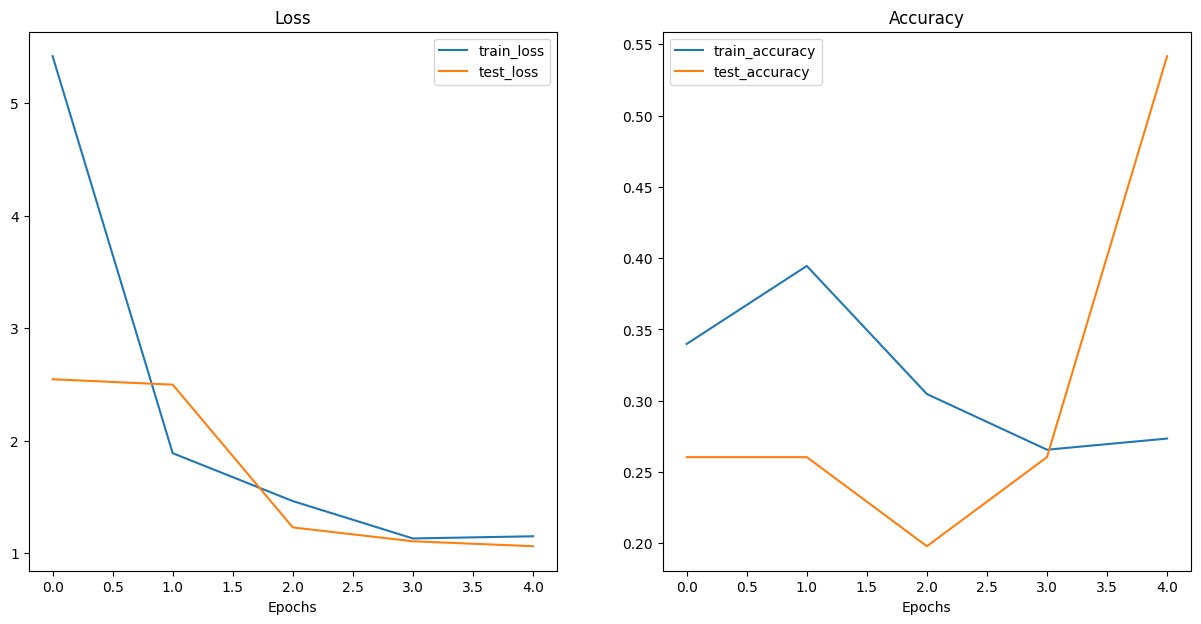

In [42]:
from helper_functions import plot_loss_curves

# Plot our ViT model's loss curves
plot_loss_curves(results)

模型的效果不好, 是因为训练数据集太小. 原论文在ImageNet-1k上训练, 该数据集有100万张图片, 而我们使用的数据集不到一万. 因此模型会严重地 underfitting.

我们可以尝试 transfer learning, 使用预训练的模型, 然后在我们的小数据集上微调. 这样可以让模型在小数据集上也有不错的表现.

# 5. 使用预训练的 ViT 模型

In [43]:
pretrained_vit_weights = torchvision.models.ViT_B_16_Weights.DEFAULT
pretrained_vit = torchvision.models.vit_b_16(weights=pretrained_vit_weights).to(device)

for param in pretrained_vit.parameters():
    param.requires_grad = False

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to C:\Users\81456/.cache\torch\hub\checkpoints\vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:09<00:00, 36.2MB/s] 


In [45]:
pretrained_vit.heads

Sequential(
  (head): Linear(in_features=768, out_features=1000, bias=True)
)

In [51]:
set_seeds()
pretrained_vit.heads = nn.Sequential(
    nn.Linear(in_features=768, out_features=len(class_names)).to(device)
).to(device)

In [52]:
pretrained_vit.heads

Sequential(
  (0): Linear(in_features=768, out_features=3, bias=True)
)

In [53]:
show_model_summary(pretrained_vit, (BATCH_SIZE, 3, 224, 224))

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
VisionTransformer (VisionTransformer)                        [32, 3, 224, 224]    [32, 3]              768                  Partial
├─Conv2d (conv_proj)                                         [32, 3, 224, 224]    [32, 768, 14, 14]    (590,592)            False
├─Encoder (encoder)                                          [32, 197, 768]       [32, 197, 768]       151,296              False
│    └─Dropout (dropout)                                     [32, 197, 768]       [32, 197, 768]       --                   --
│    └─Sequential (layers)                                   [32, 197, 768]       [32, 197, 768]       --                   False
│    │    └─EncoderBlock (encoder_layer_0)                   [32, 197, 768]       [32, 197, 768]       (7,087,872)          False
│    │    └─EncoderBlock (encoder_layer_1)                   [32, 197, 768]       [32, 

In [54]:
pretrained_transform = pretrained_vit_weights.transforms()
print(pretrained_transform)

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [57]:
train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(train_dir= train_dir, test_dir= test_dir, train_transform=pretrained_transform, test_transform=pretrained_transform, batch_size= BATCH_SIZE, num_workers=0)

In [58]:
optimizer = torch.optim.Adam(params=pretrained_vit.parameters(), lr=3e-3, weight_decay=0.3)
loss_fn = nn.CrossEntropyLoss()

epochs = 10

pretrained_results = engine.train(pretrained_vit, train_dataloader, test_dataloader, optimizer, loss_fn, epochs, device)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 0.4971 | train_acc: 0.8008 | test_loss: 0.2193 | test_acc: 0.9280
Epoch: 2 | train_loss: 0.1490 | train_acc: 0.9570 | test_loss: 0.1928 | test_acc: 0.9280
Epoch: 3 | train_loss: 0.1995 | train_acc: 0.8555 | test_loss: 0.2040 | test_acc: 0.9280
Epoch: 4 | train_loss: 0.0651 | train_acc: 0.9883 | test_loss: 0.2174 | test_acc: 0.8873
Epoch: 5 | train_loss: 0.0718 | train_acc: 0.9922 | test_loss: 0.1881 | test_acc: 0.9176
Epoch: 6 | train_loss: 0.0952 | train_acc: 0.9961 | test_loss: 0.2144 | test_acc: 0.9384
Epoch: 7 | train_loss: 0.0741 | train_acc: 1.0000 | test_loss: 0.2086 | test_acc: 0.9384
Epoch: 8 | train_loss: 0.0924 | train_acc: 1.0000 | test_loss: 0.2101 | test_acc: 0.9384
Epoch: 9 | train_loss: 0.0761 | train_acc: 1.0000 | test_loss: 0.2099 | test_acc: 0.9384
Epoch: 10 | train_loss: 0.0741 | train_acc: 0.9961 | test_loss: 0.2161 | test_acc: 0.9081


d:\PythonProjects\learn-ml\.venv\Lib\site-packages\torch\__init__.py:2271: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if not condition:


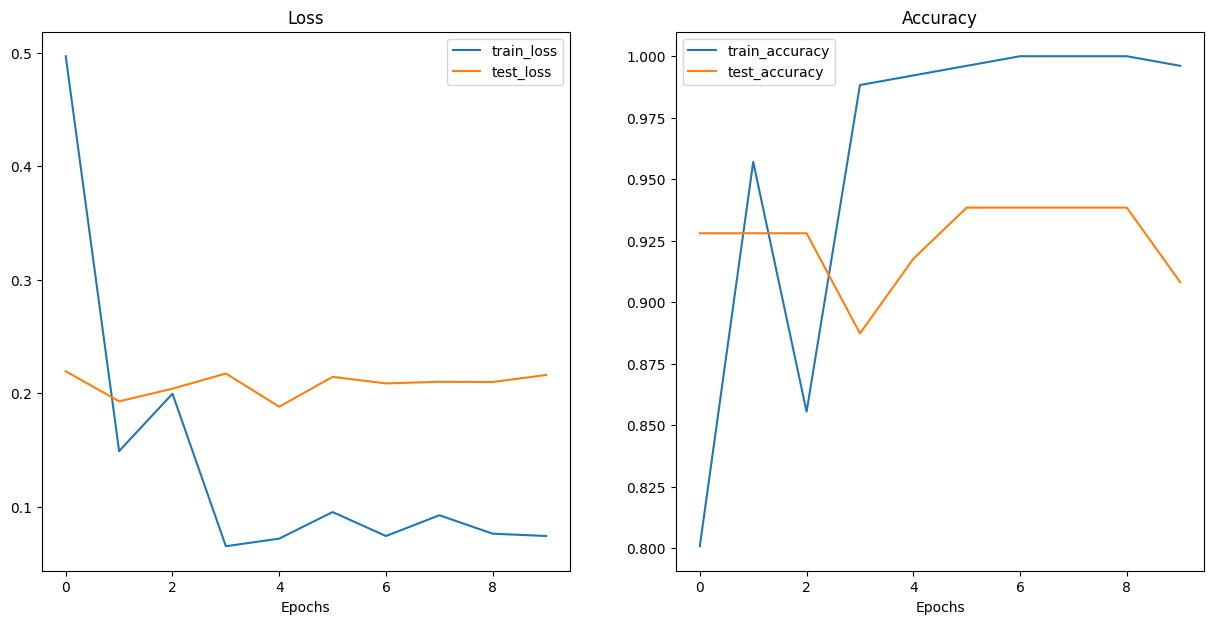

In [59]:
plot_loss_curves(pretrained_results)

In [60]:
from going_modular import utils

utils.save_model(model=pretrained_vit,
                 target_dir="models",
                 model_name="08_pretrained_vit_feature_extractor_pizza_steak_sushi.pt")

[INFO] Saving model to: models\08_pretrained_vit_feature_extractor_pizza_steak_sushi.pt


In [62]:
from pathlib import Path

model_size = Path("models/08_pretrained_vit_feature_extractor_pizza_steak_sushi.pt").stat().st_size // (1024*1024)
print(f"model size: {model_size} MB")

model size: 327 MB


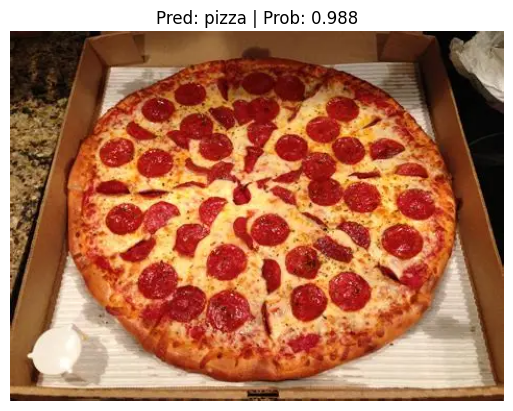

In [63]:
# predict on custom image
from going_modular import predictions
custom_image_path = "data/test_pizza.png"

predictions.pred_and_plot_image(model=pretrained_vit,
                    image_path=custom_image_path,
                    class_names=class_names)